# 5 — Prédire les 24 températures du lendemain puis leur maximum

**Question :** Une décomposition de la cible en 24 heures aide-t-elle davantage qu'une prévision directe de Tmax ?

## Protocole commun

Prévision émise à **00 h UTC du jour cible** : toutes les entrées proviennent de la veille
ou de jours antérieurs, avec une dernière observation à 23 h UTC. La cible est le maximum
des 24 températures horaires du jour cible UTC. ERA5 est une réanalyse disponible avec retard :
cette étude rétrospective ne simule pas la disponibilité d'un service de prévision en direct.

Le fichier `experiments/protocol.json` fixe les hypothèses et les paramètres. On évalue trois
fenêtres successives couvrant 2025, avec entraînement croissant. Dans chaque fenêtre,
les 90 derniers jours de développement servent à l'arrêt anticipé ; une journée est purgée
aux frontières. On réentraîne ensuite sur le développement avec le nombre d'arbres retenu.
Le choix entre variantes se fait sur la MAE pondérée par les effectifs des fenêtres 2025,
**avant** l'évaluation sur janvier–septembre 2026. La persistance reste une référence séparée.

L'année 2026 ayant déjà été consultée auparavant, ses résultats sont exploratoires.
Les modifications du protocole doivent produire une nouvelle expérience et un nouveau commit.
Aucun hyperparamètre n'est ajusté pour obtenir un meilleur score sur 2026.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "flake.nix").exists())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from research_features import load_research_data, protocol
from research_evaluation import evaluate_suite, summarize_cv
from research_reporting import report, plot_cells
pd.set_option("display.max_columns", 20)


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## Variables et hypothèse

Les entrées sont fixées : agrégats locaux, dynamique horaire, gradients et amont du vent.
On apprend soit une Tmax, soit les 24 températures horaires UTC de J+1 ; le maximum de
ces 24 prévisions devient la Tmax prédite. Les cibles horaires sont construites par jointure
sur la date cible et contrôlées contre la Tmax réelle ; elles ne figurent jamais dans les entrées.

Pour XGBoost, on entraîne 24 régresseurs, chacun avec son propre arrêt anticipé sur la
validation interne, puis son réentraînement sur la période de développement. Ridge gère
les 24 sorties dans le même pipeline. Aucun modèle ne reçoit les heures déjà observées de J+1.
Cette approche ne garantit pas une courbe physiquement cohérente et le maximum est non linéaire :
l'expérience doit juger son effet, sans supposer une amélioration.

In [2]:
frame, groups, cells, data_path = load_research_data(spatial=True)
print(f"{len(frame)} paires : {frame['target_date'].min().date()} → {frame['target_date'].max().date()}")
display(pd.DataFrame([{"groupe": k, "nombre_variables": len(v)} for k, v in groups.items()]))
display(frame[["date", "target_date", "issue_time", "last_observation_time", "temperature_max", "tmax_next_day"]].head())
assert (frame["last_observation_time"] < frame["issue_time"]).all()


994 paires : 2024-01-04 → 2026-09-23


,groupe,nombre_variables
0,daily,18
1,hourly,28
2,local_raw,28
3,regional_raw,28
4,physics,10
5,upwind,8


,date,target_date,issue_time,last_observation_time,temperature_max,tmax_next_day
0,2024-01-03,2024-01-04,2024-01-04 00:00:00+00:00,2024-01-03 23:00:00+00:00,12.7,13.2
1,2024-01-04,2024-01-05,2024-01-05 00:00:00+00:00,2024-01-04 23:00:00+00:00,13.2,10.8
2,2024-01-05,2024-01-06,2024-01-06 00:00:00+00:00,2024-01-05 23:00:00+00:00,10.8,9.3
3,2024-01-06,2024-01-07,2024-01-07 00:00:00+00:00,2024-01-06 23:00:00+00:00,9.3,6.6
4,2024-01-07,2024-01-08,2024-01-08 00:00:00+00:00,2024-01-07 23:00:00+00:00,6.6,3.8


In [3]:
features = groups["daily"] + groups["hourly"] + groups["physics"] + groups["upwind"]
variants = {
    "xgb_direct_tmax": {"columns": features},
    "xgb_24h_then_max": {"columns": features, "target": "hourly24"},
    "ridge_direct_tmax": {"columns": features, "algorithm": "ridge"},
    "ridge_24h_then_max": {"columns": features, "algorithm": "ridge", "target": "hourly24"},
}


## Expérience et enregistrement

Le code commun est dans `scripts/research_features.py` et `scripts/research_evaluation.py`.
Chaque variante utilise les mêmes lignes ; les colonnes et les paramètres sont explicitement
enregistrés avec les nombres d'arbres, les empreintes du dataset et du code.
Les températures restent en °C. XGBoost ne reçoit pas de standardisation globale ; Ridge
ajuste son standardiseur uniquement sur la période d'entraînement de chaque fenêtre.

In [4]:
scores, predictions, lag_scores, intervals, selected, output = evaluate_suite(
    frame, variants, "05_hourly_targets", data_path
)


05_hourly_targets — cv_2025_spring : 120 jours


05_hourly_targets — cv_2025_summer : 123 jours


05_hourly_targets — cv_2025_autumn : 122 jours


Choix figé sur les fenêtres 2025 : ridge_24h_then_max


05_hourly_targets — test_2026 : 266 jours


## Résultats : niveau, variations et pics

La MAE globale est la métrique principale. Les fortes variations sont définies **avant** les résultats
par |Tmax(J+1) − Tmax(J)| ≥ 4 °C, avec refroidissements et réchauffements séparés.
Les journées chaudes utilisent le 90e percentile des cibles du développement de chaque fenêtre,
jamais un seuil calculé sur le test. Il ne s'agit pas d'une définition de canicule.

Le gain positif signifie une erreur inférieure à la persistance. Les intervalles descriptifs
par bootstrap de blocs de sept jours tiennent partiellement compte de l'autocorrélation,
sans garantir la généralisation à d'autres années ni corriger les comparaisons multiples.

Moyenne pondérée des trois fenêtres 2025 (choix du modèle) :


,MAE_C,MAE_large_changes_C,n,n_large_changes,gain_vs_persistence_C
variant,,,,,
persistence,2.176,5.575,365,55,0.000
xgb_direct_tmax,2.046,3.707,365,55,0.130
xgb_24h_then_max,2.014,3.707,365,55,0.162
ridge_direct_tmax,1.930,3.610,365,55,0.247
ridge_24h_then_max,1.924,3.641,365,55,0.252


Choix sur 2025, maintenu pour 2026 : ridge_24h_then_max
Test descriptif 2026 — MAE en °C et effectifs :


,MAE_C,RMSE_C,bias_C,n,n_large_changes,MAE_large_changes_C,MAE_cooling_C,MAE_warming_C,MAE_warm_days_C,gain_vs_persistence_C
variant,,,,,,,,,,
persistence,2.039,2.778,-0.091,266,41,5.683,5.695,5.670,2.379,0.000
xgb_direct_tmax,2.289,3.179,-1.305,266,41,3.562,2.438,4.741,3.613,-0.250
xgb_24h_then_max,2.217,3.028,-1.273,266,41,3.560,2.350,4.830,3.359,-0.178
ridge_direct_tmax,1.896,2.508,-0.507,266,41,3.689,2.494,4.944,2.295,0.142
ridge_24h_then_max,1.922,2.575,-0.773,266,41,3.705,2.302,5.178,2.360,0.117


Gain vs persistance : intervalle descriptif par blocs de 7 jours (sans correction pour comparaisons multiples) :


,gain_low_C,gain_high_C
variant,,
persistence,0.000,0.000
ridge_24h_then_max,-0.073,0.306
ridge_direct_tmax,-0.035,0.329
xgb_24h_then_max,-0.573,0.189
xgb_direct_tmax,-0.703,0.153


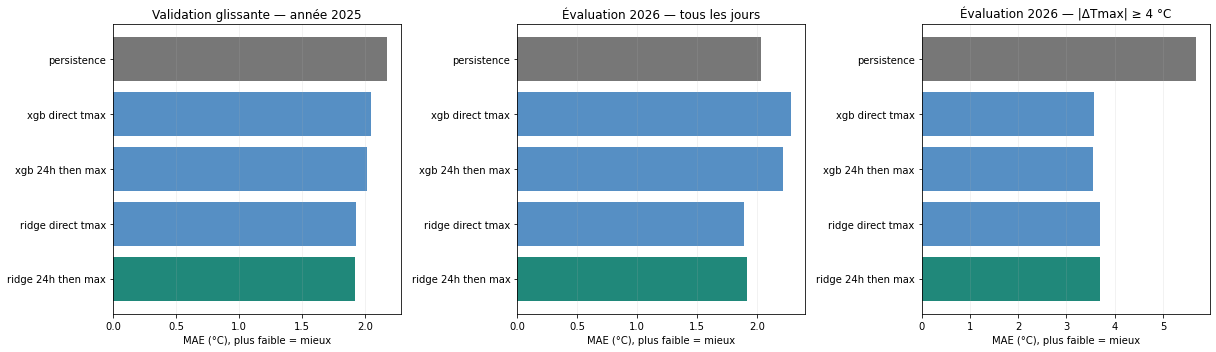

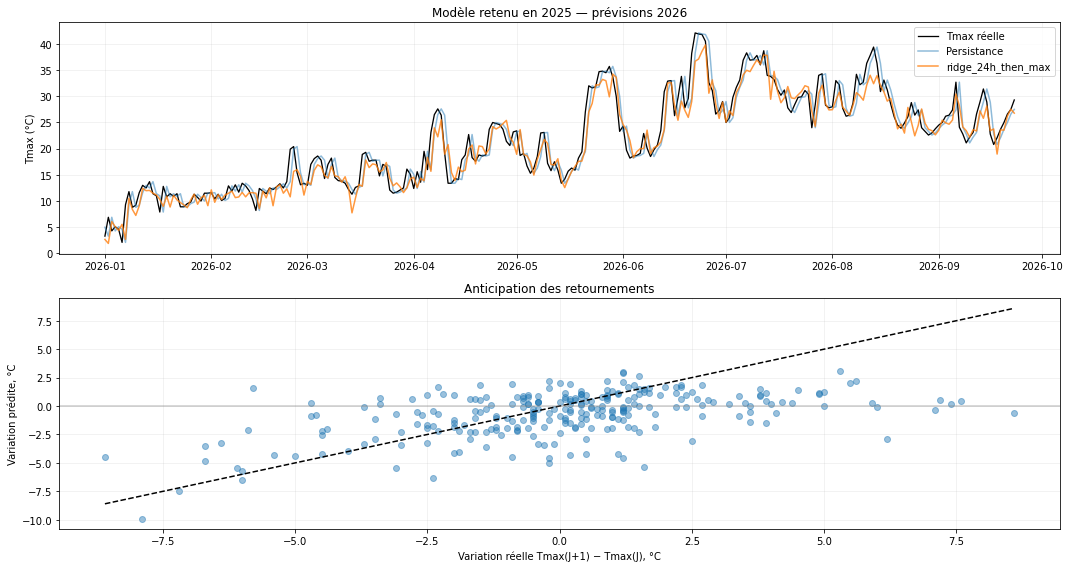

Diagnostic de décalage : vérité comparée à date_cible + décalage. -1 = la veille.


,MAE_truth_date_plus_-1_C,MAE_truth_date_plus_0_C,MAE_truth_date_plus_1_C
variant,,,
persistence,0.000,2.040,3.060
xgb_direct_tmax,1.816,2.292,3.001
xgb_24h_then_max,1.765,2.221,2.949
ridge_direct_tmax,1.481,1.894,2.796
ridge_24h_then_max,1.524,1.919,2.834


Un minimum à -1 signale une ressemblance avec la veille ; il ne prouve pas une erreur de dates.
MAE par mois cible, mêmes jours pour tous les modèles :


variant,persistence,ridge_24h_then_max,ridge_direct_tmax,xgb_24h_then_max,xgb_direct_tmax
month,,,,,
2026-01,1.687,1.427,1.395,1.255,1.371
2026-02,1.454,1.580,1.553,1.305,1.198
2026-03,1.526,1.535,1.477,1.611,1.547
2026-04,2.423,2.395,2.371,2.113,2.089
2026-05,2.158,2.246,2.204,2.594,2.606
2026-06,2.770,2.432,2.435,3.205,3.437
2026-07,2.129,1.828,1.824,3.365,3.664
2026-08,2.045,2.082,2.075,2.612,2.833
2026-09,2.170,1.714,1.674,1.696,1.605


Les effectifs des fortes variations sont limités ; pas de conclusion causale sur les fronts météorologiques.


In [5]:
report(scores, predictions, lag_scores, intervals, selected, output)


## Géométrie du voisinage

Coordonnées des cellules réellement retournées, sans présumer une station de mesure.

,lat,lon
point,,
center,47.25,-1.50
local_east,47.25,-0.50
local_north,48.00,-1.50
local_south,46.50,-1.50
local_west,47.25,-2.50
regional_east,47.25,1.00
regional_north,49.00,-1.50
regional_south,45.50,-1.50
regional_west,47.25,-4.25


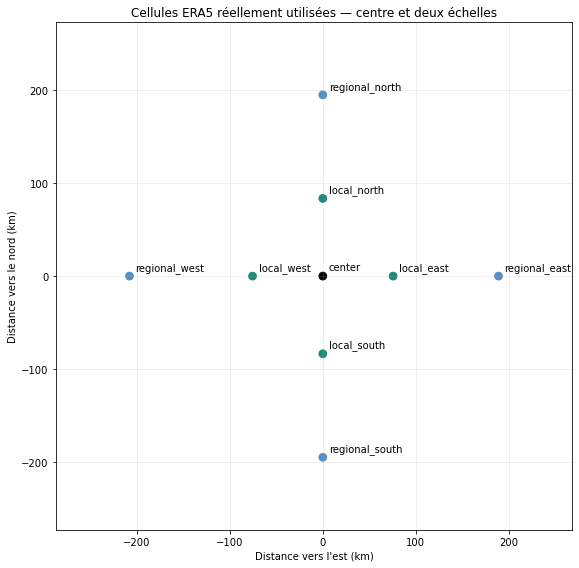

In [6]:
display(cells)
plot_cells(cells, output)


## Interprétation et limites

Un gain global sans gain sur les refroidissements ne valide pas l'hypothèse d'anticipation des fronts.
À l'inverse, un gain sur quelques pics peut être instable : regarder les effectifs, les trois fenêtres
2025 et les mois de 2026. Ne pas confondre mauvaise information, décalage d'alignement et faible
extrapolation du modèle. Cette étude ne mesure pas directement les fronts ni les masses d'air.
L'absence de gain avec ces variables ne prouve pas que toute information spatiale est inutile.

Avec moins de trois années et environ mille journées, les réseaux neuronaux ne sont pas la prochaine
étape automatique. Une confirmation sur des années supplémentaires et des prévisions archivées
disponibles à l'heure d'émission sera nécessaire avant une conclusion opérationnelle.

Sources : [Open-Meteo, réanalyse et paramètres](https://open-meteo.com/en/docs/historical-weather-api),
[évaluation temporelle](https://scikit-learn.org/stable/modules/cross_validation.html),
[complexité et régularisation XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html).

In [7]:
cv = summarize_cv(scores)
test = scores.loc[scores["window"].eq("test_2026")].set_index("variant")
print(f"Variante choisie en 2025 : {selected}")
print(f"MAE 2025 : {cv.loc[selected, 'MAE_C']:.3f} °C ; persistance : {cv.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 : {test.loc[selected, 'MAE_C']:.3f} °C ; persistance : {test.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 sur fortes variations : {test.loc[selected, 'MAE_large_changes_C']:.3f} °C ; n = {test.loc[selected, 'n_large_changes']}")
print(f"Traces et figures enregistrées dans {output.relative_to(PROJECT_ROOT)}")


Variante choisie en 2025 : ridge_24h_then_max
MAE 2025 : 1.924 °C ; persistance : 2.176 °C
MAE 2026 : 1.922 °C ; persistance : 2.039 °C
MAE 2026 sur fortes variations : 3.705 °C ; n = 41
Traces et figures enregistrées dans experiments/results/05_hourly_targets
